In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
orders = pd.read_csv(
    "../data/processed/orders_clean.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

customers = pd.read_csv("../data/processed/customers_clean.csv")
order_items = pd.read_csv("../data/processed/order_items_clean.csv")
payments = pd.read_csv("../data/processed/payments_clean.csv")
reviews = pd.read_csv("../data/processed/reviews_clean.csv")
products = pd.read_csv("../data/processed/products_clean.csv")
sellers = pd.read_csv("../data/processed/sellers_clean.csv")
category_translation = pd.read_csv(
    "../data/processed/category_translation_clean.csv"
)

print("Processed data loaded successfully!")
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order items:", order_items.shape)
print("Payments:", payments.shape)

Processed data loaded successfully!
Orders: (99441, 11)
Customers: (99441, 5)
Order items: (112650, 7)
Payments: (103886, 8)


In [4]:
# Order-level merchandise and freight values
item_order_value = (
    order_items
    .groupby("order_id")
    .agg(
        product_sales=("price", "sum"),
        freight=("freight_value", "sum")
    )
    .reset_index()
)

item_order_value["item_total"] = (
    item_order_value["product_sales"]
    + item_order_value["freight"]
)


# Order-level payment value
payment_order_value = (
    payments
    .groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum")
    )
    .reset_index()
)


# Compare the two
value_check = item_order_value.merge(
    payment_order_value,
    on="order_id",
    how="inner"
)

value_check["difference"] = (
    value_check["payment_total"]
    - value_check["item_total"]
)

value_check[
    ["product_sales", "freight", "item_total", "payment_total", "difference"]
].describe()

,product_sales,freight,item_total,payment_total,difference
count,98665.000000,98665.000000,98665.000000,98665.000000,98665.000000
mean,137.754105,22.823707,160.577812,160.606904,0.029092
std,210.646213,21.650971,220.467197,220.484252,1.129221
min,0.850000,0.000000,9.590000,9.590000,-51.620000
25%,45.900000,13.850000,61.980000,62.000000,0.000000
50%,86.900000,17.170000,105.290000,105.290000,0.000000
75%,149.900000,24.040000,176.870000,176.880000,0.000000
max,13440.000000,1794.960000,13664.080000,13664.080000,182.810000


GMV = Σ order_items.price
Freight = Σ order_items.freight_value
Order Value = Product Sales + Freight
Customer Payment = Σ payments.payment_value

In [5]:
orders["has_items"] = orders["order_id"].isin(order_items["order_id"])
orders["has_payment"] = orders["order_id"].isin(payments["order_id"])

print("Total orders:", len(orders))
print("Orders without items:", (~orders["has_items"]).sum())
print("Orders without payments:", (~orders["has_payment"]).sum())
print(
    "Orders with both items and payments:",
    (orders["has_items"] & orders["has_payment"]).sum()
)

Total orders: 99441
Orders without items: 775
Orders without payments: 1
Orders with both items and payments: 98665


In [6]:
print("ORDERS WITHOUT ITEMS")
print(
    orders.loc[
        ~orders["has_items"],
        "order_status"
    ].value_counts()
)

print("\nORDERS WITHOUT PAYMENTS")
print(
    orders.loc[
        ~orders["has_payment"],
        "order_status"
    ].value_counts()
)

ORDERS WITHOUT ITEMS
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

ORDERS WITHOUT PAYMENTS
order_status
delivered    1
Name: count, dtype: int64


In [7]:
no_payment_order = orders.loc[
    ~orders["has_payment"],
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
]

no_payment_order

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-09-15 12:16:38,2016-11-09 07:47:38


In [8]:
no_payment_order_id = no_payment_order.iloc[0]["order_id"]

order_items[
    order_items["order_id"] == no_payment_order_id
]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
84389,bfbd0f9bdef84302105ad712db648a6c,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84390,bfbd0f9bdef84302105ad712db648a6c,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84391,bfbd0f9bdef84302105ad712db648a6c,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83


In [9]:
gmv_by_status = (
    orders[["order_id", "order_status"]]
    .merge(
        item_order_value[["order_id", "product_sales"]],
        on="order_id",
        how="inner"
    )
    .groupby("order_status")
    .agg(
        orders=("order_id", "nunique"),
        GMV=("product_sales", "sum")
    )
    .sort_values("GMV", ascending=False)
)

gmv_by_status

,orders,GMV
order_status,,
delivered,96478,13221498.11
shipped,1106,150727.44
canceled,461,95235.27
invoiced,312,61526.37
processing,301,60439.22
unavailable,6,2007.69
approved,2,209.60


### KPI Definitions

For this analysis:

- **GMV (Gross Merchandise Value)** = sum of `order_items.price` for orders with `order_status = 'delivered'`.
- **Freight** = sum of `order_items.freight_value` for delivered orders.
- **Order Value** = GMV + Freight.
- **Customer Payment** = sum of `payments.payment_value` and is analyzed separately from GMV.
- **AOV (Average Order Value)** = delivered-order GMV / number of delivered orders.

Only delivered orders are used for the primary GMV and AOV metrics because they represent completed transactions.

Non-delivered orders are retained for separate analyses such as cancellation, fulfillment, and order-status performance.

In [10]:
# Build delivered-order analysis base

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_items = (
    delivered_orders[
        ["order_id", "customer_id", "order_purchase_timestamp"]
    ]
    .merge(
        order_items,
        on="order_id",
        how="inner"
    )
)

print("Delivered orders:", delivered_orders["order_id"].nunique())
print("Delivered order-item rows:", len(delivered_items))

Delivered orders: 96478
Delivered order-item rows: 110197


In [11]:
# Core business KPIs

total_gmv = delivered_items["price"].sum()
total_freight = delivered_items["freight_value"].sum()
total_order_value = total_gmv + total_freight

total_orders = delivered_orders["order_id"].nunique()

delivered_customer_ids = delivered_orders[
    ["order_id", "customer_id"]
].merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

total_customers = delivered_customer_ids[
    "customer_unique_id"
].nunique()

aov = total_gmv / total_orders

print(f"GMV: {total_gmv:,.2f}")
print(f"Freight: {total_freight:,.2f}")
print(f"Order Value: {total_order_value:,.2f}")
print(f"Delivered Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"AOV: {aov:,.2f}")

GMV: 13,221,498.11
Freight: 2,198,275.64
Order Value: 15,419,773.75
Delivered Orders: 96,478
Unique Customers: 93,358
AOV: 137.04


## Core Business KPIs

Primary business metrics are calculated using delivered orders only.

- **GMV:** 13,221,498.11
- **Freight:** 2,198,275.64
- **Order Value:** 15,419,773.75
- **Delivered Orders:** 96,478
- **Unique Customers:** 93,358
- **Average Order Value (AOV):** 137.04

`customer_unique_id` is used to identify unique customers because a customer may have multiple `customer_id` values across different orders.

In [12]:
print(
    "First delivered order:",
    delivered_orders["order_purchase_timestamp"].min()
)

print(
    "Last delivered order:",
    delivered_orders["order_purchase_timestamp"].max()
)

First delivered order: 2016-09-15 12:16:38
Last delivered order: 2018-08-29 15:00:37


In [13]:
delivered_orders["purchase_month"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_metrics = (
    delivered_orders[
        ["order_id", "purchase_month"]
    ]
    .merge(
        order_items[
            ["order_id", "price", "freight_value"]
        ],
        on="order_id",
        how="inner"
    )
    .groupby("purchase_month")
    .agg(
        GMV=("price", "sum"),
        Freight=("freight_value", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_metrics["AOV"] = (
    monthly_metrics["GMV"] / monthly_metrics["Orders"]
)

monthly_metrics

,purchase_month,GMV,Freight,Orders,AOV
0,2016-09-01,134.97,8.49,1,134.970000
1,2016-10-01,40325.11,6165.55,265,152.170226
2,2016-12-01,10.90,8.72,1,10.900000
3,2017-01-01,111798.36,15684.01,750,149.064480
4,2017-02-01,234223.40,37015.92,1653,141.695947
5,2017-03-01,359198.85,55132.10,2546,141.083602
6,2017-04-01,340669.68,50142.72,2303,147.924307
7,2017-05-01,489338.25,77513.15,3546,137.997250
8,2017-06-01,421923.37,68127.00,3135,134.584807
9,2017-07-01,481604.52,84694.56,3872,124.381333


### Analysis Time Window

The raw dataset spans from September 2016 to August 2018.

However, the early 2016 period contains very sparse transaction activity, including only one delivered order in September and December and no delivered orders in November.

In addition, August 2018 may be affected by right-censoring because recently purchased orders may not yet have reached `delivered` status by the end of the dataset.

Therefore, the primary monthly trend analysis focuses on the more stable period from **January 2017 through July 2018**. The excluded months are retained in the dataset but are not used for the main trend interpretation.

In [14]:
monthly_trend = monthly_metrics[
    (monthly_metrics["purchase_month"] >= "2017-01-01")
    & (monthly_metrics["purchase_month"] <= "2018-07-01")
].copy()

monthly_trend

,purchase_month,GMV,Freight,Orders,AOV
3,2017-01-01,111798.36,15684.01,750,149.064480
4,2017-02-01,234223.40,37015.92,1653,141.695947
5,2017-03-01,359198.85,55132.10,2546,141.083602
6,2017-04-01,340669.68,50142.72,2303,147.924307
7,2017-05-01,489338.25,77513.15,3546,137.997250
8,2017-06-01,421923.37,68127.00,3135,134.584807
9,2017-07-01,481604.52,84694.56,3872,124.381333
10,2017-08-01,554699.70,91132.66,4193,132.291844
11,2017-09-01,607399.67,93677.82,4150,146.361366
12,2017-10-01,648247.65,102869.36,4478,144.762762


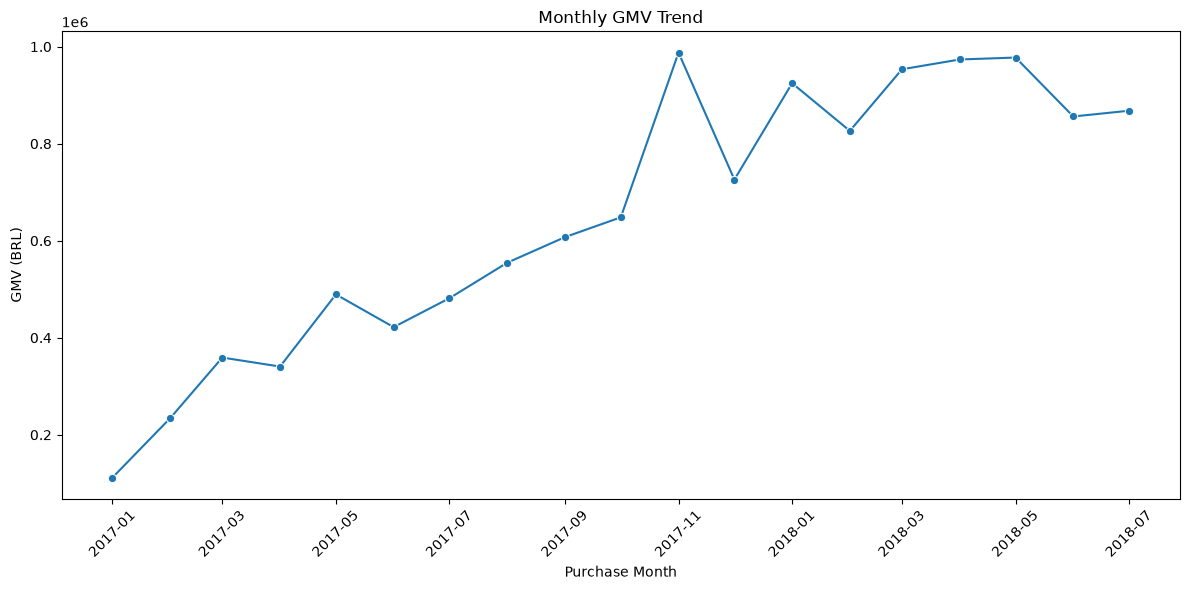

In [15]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_trend,
    x="purchase_month",
    y="GMV",
    marker="o"
)

plt.title("Monthly GMV Trend")
plt.xlabel("Purchase Month")
plt.ylabel("GMV (BRL)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly GMV Trend

Monthly GMV shows a strong overall upward trend from January 2017 through mid-2018.

- GMV increased substantially throughout 2017, reaching a notable peak in November 2017.
- A decline followed in December 2017.
- During 2018, monthly GMV remained at a substantially higher level than in early 2017, generally ranging between approximately 0.8 and 1.0 million BRL.
- This suggests that the marketplace experienced meaningful growth in transaction value over the analysis period.

Further analysis is needed to determine whether this growth was primarily driven by an increase in order volume, changes in average order value(AOV), or both.

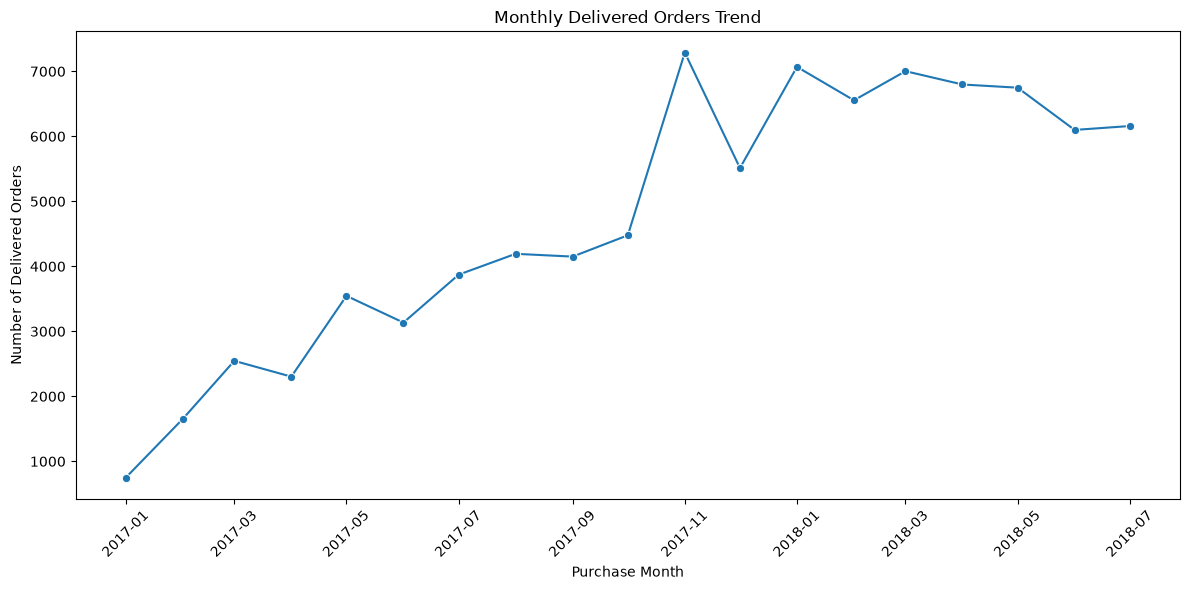

In [16]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_trend,
    x="purchase_month",
    y="Orders",
    marker="o"
)

plt.title("Monthly Delivered Orders Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Delivered Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Delivered Orders Trend

Monthly delivered order volume follows a pattern similar to GMV.

- Delivered orders increased substantially throughout 2017, reaching a peak in November 2017.
- Order volume remained at a much higher level throughout 2018 compared with early 2017.
- The close similarity between the order-volume trend and the GMV trend suggests that GMV growth was largely driven by increasing transaction volume.

To determine whether changes in customer spending per order also contributed to GMV growth, the next step is to examine the monthly Average Order Value (AOV).

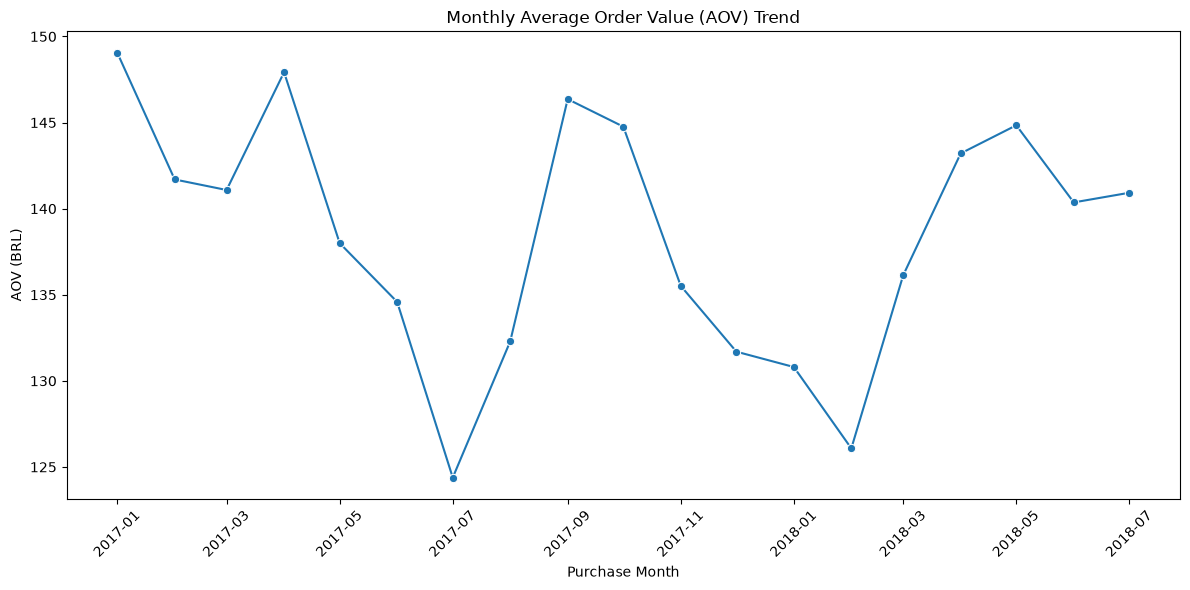

In [17]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_trend,
    x="purchase_month",
    y="AOV",
    marker="o"
)

plt.title("Monthly Average Order Value (AOV) Trend")
plt.xlabel("Purchase Month")
plt.ylabel("AOV (BRL)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Average Order Value (AOV) Trend

Unlike GMV and delivered order volume, AOV does not show a sustained upward trend over the analysis period.

- Monthly AOV fluctuated within a relatively stable range of approximately 124–149 BRL.
- Several temporary increases and declines occurred, but there was no persistent increase in customer spending per order.
- In contrast, both GMV and delivered order volume increased substantially over time.

Taken together, these results suggest that the growth in GMV was driven primarily by higher order volume rather than a sustained increase in average spending per order.

In [18]:
customer_order_frequency = (
    delivered_orders[
        ["order_id", "customer_id"]
    ]
    .merge(
        customers[
            ["customer_id", "customer_unique_id"]
        ],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

total_customers = len(customer_order_frequency)

one_time_customers = (
    customer_order_frequency["order_count"] == 1
).sum()

repeat_customers = (
    customer_order_frequency["order_count"] > 1
).sum()

repeat_customer_rate = (
    repeat_customers / total_customers * 100
)

print("Unique customers:", total_customers)
print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)
print(f"Repeat customer rate: {repeat_customer_rate:.2f}%")
print(
    "Maximum orders by one customer:",
    customer_order_frequency["order_count"].max()
)

Unique customers: 93358
One-time customers: 90557
Repeat customers: 2801
Repeat customer rate: 3.00%
Maximum orders by one customer: 15


### Repeat Customer Analysis

Among 93,358 unique customers with delivered orders:

- 90,557 customers (97.0%) placed only one delivered order.
- 2,801 customers (3.0%) placed more than one delivered order.
- The maximum number of delivered orders placed by a single customer was 15.

This indicates that repeat purchasing is relatively uncommon within the observed dataset, with the customer base dominated by one-time purchasers.

The 3.0% metric should be interpreted as a **repeat customer rate**, rather than a formal retention rate, because customers have different observation windows and no cohort-based retention period has yet been defined.

In [19]:
order_frequency_distribution = (
    customer_order_frequency["order_count"]
    .value_counts()
    .sort_index()
    .rename_axis("order_count")
    .reset_index(name="customers")
)

order_frequency_distribution["customer_pct"] = (
    order_frequency_distribution["customers"]
    / total_customers
    * 100
)

order_frequency_distribution

,order_count,customers,customer_pct
0,1,90557,96.999722
1,2,2573,2.756057
2,3,181,0.193877
3,4,28,0.029992
4,5,9,0.009640
5,6,5,0.005356
6,7,3,0.003213
7,9,1,0.001071
8,15,1,0.001071


In [20]:
def frequency_segment(order_count):
    if order_count == 1:
        return "1 order"
    elif order_count == 2:
        return "2 orders"
    elif order_count == 3:
        return "3 orders"
    else:
        return "4+ orders"

customer_order_frequency["frequency_segment"] = (
    customer_order_frequency["order_count"]
    .apply(frequency_segment)
)

frequency_segments = (
    customer_order_frequency["frequency_segment"]
    .value_counts()
    .reindex(["1 order", "2 orders", "3 orders", "4+ orders"])
    .reset_index()
)

frequency_segments.columns = ["frequency_segment", "customers"]

frequency_segments["customer_pct"] = (
    frequency_segments["customers"]
    / total_customers
    * 100
)

frequency_segments

,frequency_segment,customers,customer_pct
0,1 order,90557,96.999722
1,2 orders,2573,2.756057
2,3 orders,181,0.193877
3,4+ orders,47,0.050344


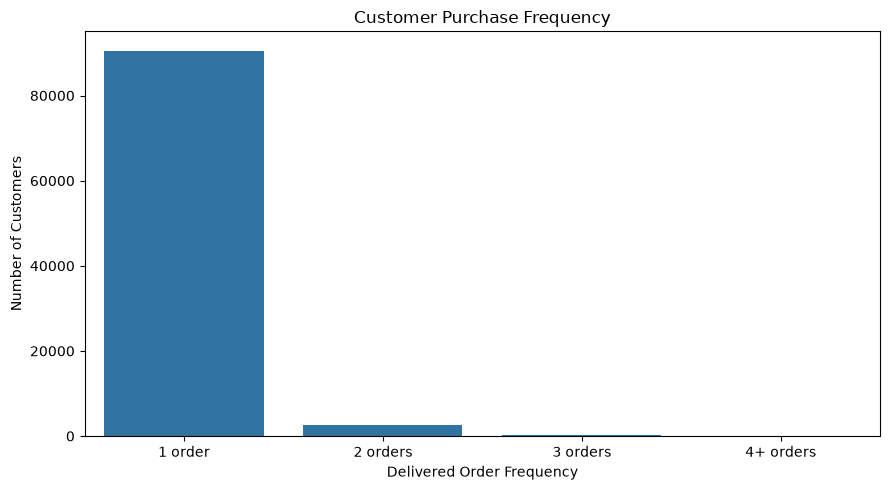

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=frequency_segments,
    x="frequency_segment",
    y="customers"
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Delivered Order Frequency")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Customer Purchase Frequency

Customer purchasing behavior is heavily concentrated among one-time buyers.

- 97.0% of customers placed only one delivered order.
- 2.76% placed two delivered orders.
- Only 0.24% placed three or more delivered orders.
- Just 47 customers placed four or more delivered orders.

This indicates that repeat purchasing is relatively uncommon within the observed customer base. However, customer count alone does not show the economic importance of repeat customers. The next analysis compares the GMV contribution of one-time and repeat customers.

In [22]:
customer_order_frequency["customer_segment"] = np.where(
    customer_order_frequency["order_count"] == 1,
    "One-time",
    "Repeat"
)

In [23]:
customer_gmv_base = (
    delivered_orders[
        ["order_id", "customer_id"]
    ]
    .merge(
        customers[
            ["customer_id", "customer_unique_id"]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        customer_order_frequency[
            ["customer_unique_id", "customer_segment"]
        ],
        on="customer_unique_id",
        how="left"
    )
    .merge(
        order_items[
            ["order_id", "price"]
        ],
        on="order_id",
        how="inner"
    )
)

customer_gmv_base.head()

,order_id,customer_id,customer_unique_id,customer_segment,price
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,Repeat,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,One-time,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,One-time,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,One-time,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,One-time,19.90


In [24]:
customer_segment_summary = (
    customer_gmv_base
    .groupby("customer_segment")
    .agg(
        GMV=("price", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_unique_id", "nunique")
    )
    .reset_index()
)

customer_segment_summary["GMV_share_pct"] = (
    customer_segment_summary["GMV"]
    / customer_segment_summary["GMV"].sum()
    * 100
)

customer_segment_summary["AOV"] = (
    customer_segment_summary["GMV"]
    / customer_segment_summary["Orders"]
)

customer_segment_summary

,customer_segment,GMV,Orders,Customers,GMV_share_pct,AOV
0,One-time,12493089.36,90557,90557,94.490725,137.958295
1,Repeat,728408.75,5921,2801,5.509275,123.021238


### One-Time vs. Repeat Customer Value

Repeat customers represent only 3.0% of unique customers but contribute 5.51% of total GMV.

- One-time customers generate 94.49% of GMV and have an AOV of 137.96 BRL.
- Repeat customers generate 5.51% of GMV and have a lower AOV of 123.02 BRL.
- However, repeat customers generate approximately 260.05 BRL in GMV per customer, compared with 137.96 BRL for one-time customers.

This suggests that the higher economic value of repeat customers is driven primarily by greater purchase frequency rather than higher spending per order.

Although repeat customers form a small portion of the customer base, increasing repeat purchasing could represent an important growth opportunity.

In [25]:
customer_segment_summary["GMV_per_customer"] = (
    customer_segment_summary["GMV"]
    / customer_segment_summary["Customers"]
)

customer_segment_summary["orders_per_customer"] = (
    customer_segment_summary["Orders"]
    / customer_segment_summary["Customers"]
)

customer_segment_summary

,customer_segment,GMV,Orders,Customers,GMV_share_pct,AOV,GMV_per_customer,orders_per_customer
0,One-time,12493089.36,90557,90557,94.490725,137.958295,137.958295,1.000000
1,Repeat,728408.75,5921,2801,5.509275,123.021238,260.053106,2.113888


Repeat customers generate approximately 1.88× as much GMV per customer as one-time customers (260.05 BRL vs. 137.96 BRL), primarily because they place more orders on average (2.11 vs. 1.00), rather than because they spend more per order.

In [26]:
# Build an order-level geographic analysis base

geo_order_base = (
    delivered_orders[
        ["order_id", "customer_id"]
    ]
    .merge(
        customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_city",
                "customer_state"
            ]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        item_order_value[
            ["order_id", "product_sales", "freight", "item_total"]
        ],
        on="order_id",
        how="inner"
    )
)

geo_order_base.head()

,order_id,customer_id,customer_unique_id,customer_city,customer_state,product_sales,freight,item_total
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,barreiras,BA,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,19.90,8.72,28.62


In [27]:
state_summary = (
    geo_order_base
    .groupby("customer_state")
    .agg(
        GMV=("product_sales", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_unique_id", "nunique"),
        Freight=("freight", "sum")
    )
    .reset_index()
)

state_summary["AOV"] = (
    state_summary["GMV"] / state_summary["Orders"]
)

state_summary["GMV_share_pct"] = (
    state_summary["GMV"]
    / state_summary["GMV"].sum()
    * 100
)

state_summary = (
    state_summary
    .sort_values("GMV", ascending=False)
    .reset_index(drop=True)
)

state_summary.head(10)

,customer_state,GMV,Orders,Customers,Freight,AOV,GMV_share_pct
0,SP,5067633.16,40501,39156,702069.99,125.123655,38.328736
1,RJ,1759651.13,12350,11917,295750.44,142.481873,13.309015
2,MG,1552481.83,11354,11001,266409.84,136.734352,11.742102
3,RS,728897.47,5345,5168,132575.32,136.369966,5.512972
4,PR,666063.51,4923,4769,115645.29,135.296264,5.037731
5,SC,507012.13,3546,3449,88115.65,142.981424,3.834756
6,BA,493584.14,3256,3158,97553.67,151.592181,3.733194
7,DF,296498.41,2080,2019,49624.94,142.547312,2.242548
8,GO,282836.70,1957,1895,51375.65,144.525652,2.139218
9,ES,268643.45,1995,1928,49014.48,134.658371,2.031868


### Geographic GMV Concentration

GMV is highly concentrated in a small number of Brazilian states.

- São Paulo (SP) is the largest market, contributing 38.33% of total GMV with 40,501 delivered orders.
- Rio de Janeiro (RJ) and Minas Gerais (MG) contribute 13.31% and 11.74% of GMV, respectively.
- Together, the top three states account for approximately 63.38% of total GMV.
- SP has an AOV of 125.12 BRL, which is lower than several other top states.

This suggests that SP's dominant GMV contribution is driven primarily by its much larger order and customer volume rather than higher spending per order.

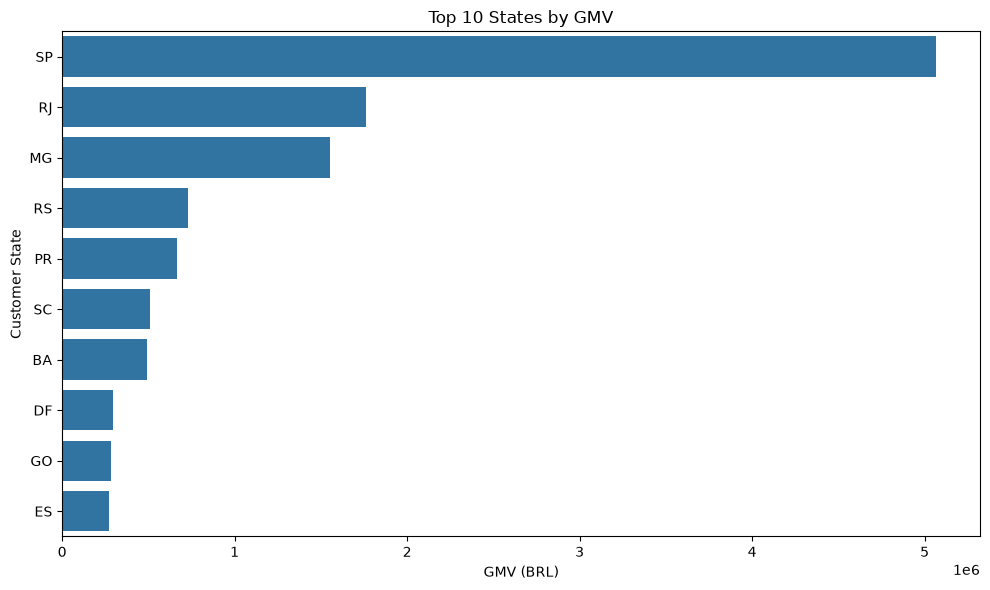

In [28]:
top10_states = state_summary.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10_states,
    x="GMV",
    y="customer_state"
)

plt.title("Top 10 States by GMV")
plt.xlabel("GMV (BRL)")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

### Top States by GMV

São Paulo (SP) is the dominant market, generating substantially more GMV than any other state. Rio de Janeiro (RJ) and Minas Gerais (MG) form the second tier, while GMV declines considerably across the remaining states.

The concentration of GMV in SP appears to be driven primarily by transaction volume rather than unusually high average order value.

GMV=orders*AOV

In [29]:
top10_comparison = state_summary.head(10).copy()

orders_range_ratio = (
    top10_comparison["Orders"].max()
    / top10_comparison["Orders"].min()
)

aov_range_ratio = (
    top10_comparison["AOV"].max()
    / top10_comparison["AOV"].min()
)

orders_cv = (
    top10_comparison["Orders"].std()
    / top10_comparison["Orders"].mean()
)

aov_cv = (
    top10_comparison["AOV"].std()
    / top10_comparison["AOV"].mean()
)

print(f"Orders max/min ratio: {orders_range_ratio:.2f}x")
print(f"AOV max/min ratio: {aov_range_ratio:.2f}x")
print(f"Orders coefficient of variation: {orders_cv:.2f}")
print(f"AOV coefficient of variation: {aov_cv:.2f}")

Orders max/min ratio: 20.70x
AOV max/min ratio: 1.21x
Orders coefficient of variation: 1.35
AOV coefficient of variation: 0.05


### Drivers of Geographic GMV Differences

The variation in GMV across the top 10 states is primarily driven by differences in order volume rather than AOV.

- The largest state has approximately 20.7× as many delivered orders as the smallest state in the top 10.
- In contrast, the highest AOV is only about 1.21× the lowest.
- Order volume has a coefficient of variation of 1.35, while AOV has a coefficient of variation of only 0.05.

This indicates that geographic GMV concentration is mainly associated with market size and transaction volume rather than large differences in spending per order.

In [31]:
# Add English product category names

products_analysis = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

products_analysis["category_english"] = (
    products_analysis["product_category_name_english"]
    .fillna(products_analysis["product_category_name_clean"])
)

products_analysis[
    [
        "product_id",
        "product_category_name",
        "product_category_name_english",
        "category_english"
    ]
].head()

,product_id,product_category_name,product_category_name_english,category_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,housewares


In [32]:
product_sales_base = (
    delivered_items[
        [
            "order_id",
            "product_id",
            "seller_id",
            "price",
            "freight_value"
        ]
    ]
    .merge(
        products_analysis[
            ["product_id", "category_english"]
        ],
        on="product_id",
        how="left"
    )
)

print("Rows:", len(product_sales_base))
print(
    "Missing category:",
    product_sales_base["category_english"].isna().sum()
)

product_sales_base.head()

Rows: 110197
Missing category: 0


,order_id,product_id,seller_id,price,freight_value,category_english
0,e481f51cbdc54678b7cc49136f2d6af7,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,45.00,27.20,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,stationery


In [33]:
category_summary = (
    product_sales_base
    .groupby("category_english")
    .agg(
        GMV=("price", "sum"),
        Orders=("order_id", "nunique"),
        Items=("product_id", "count")
    )
    .reset_index()
)

category_summary["AOV"] = (
    category_summary["GMV"]
    / category_summary["Orders"]
)

category_summary["GMV_share_pct"] = (
    category_summary["GMV"]
    / category_summary["GMV"].sum()
    * 100
)

category_summary = (
    category_summary
    .sort_values("GMV", ascending=False)
    .reset_index(drop=True)
)

category_summary.head(10)

,category_english,GMV,Orders,Items,AOV,GMV_share_pct
0,health_beauty,1233131.72,8647,9465,142.608040,9.326717
1,watches_gifts,1166176.98,5495,5859,212.225110,8.820309
2,bed_bath_table,1023434.76,9272,10953,110.379072,7.740687
3,sports_leisure,954852.55,7530,8431,126.806448,7.221969
4,computers_accessories,888724.61,6530,7644,136.098715,6.721815
5,furniture_decor,711927.69,6307,8160,112.878974,5.384622
6,housewares,615628.69,5743,6795,107.196359,4.656270
7,cool_stuff,610204.10,3559,3718,171.453807,4.615242
8,auto,578966.65,3810,4140,151.959751,4.378979
9,toys,471286.48,3804,4030,123.892345,3.564547


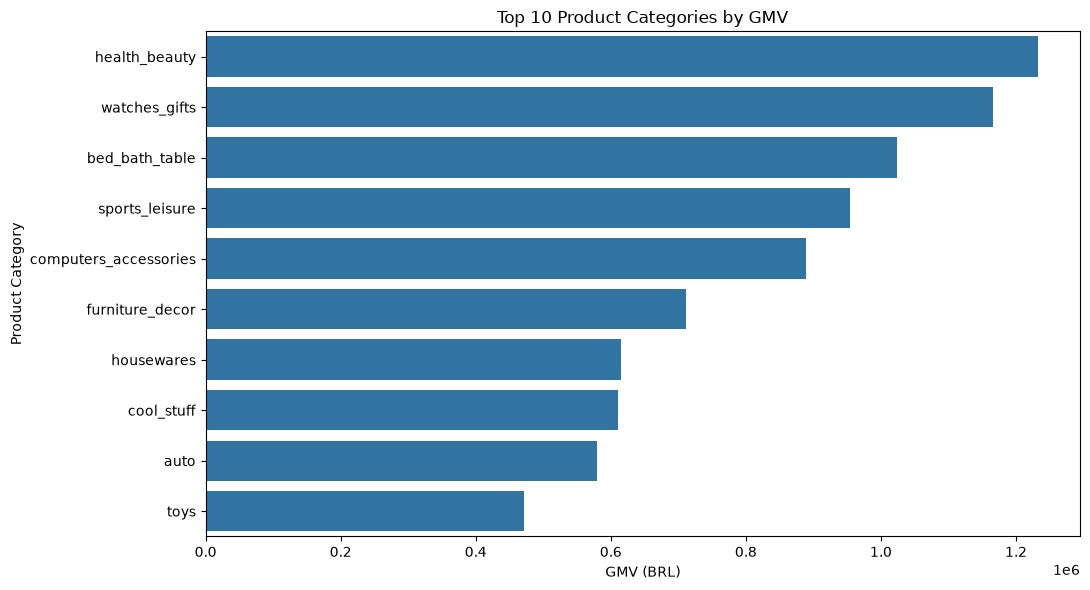

In [34]:
category_summary = category_summary.rename(
    columns={"AOV": "GMV_per_category_order"}
)
top10_categories = category_summary.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top10_categories,
    x="GMV",
    y="category_english"
)

plt.title("Top 10 Product Categories by GMV")
plt.xlabel("GMV (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

### Top Product Categories by GMV

GMV is concentrated among several major product categories, although no single category dominates the marketplace.

- `health_beauty` generates the highest GMV, followed by `watches_gifts` and `bed_bath_table`.
- The top categories differ not only in transaction volume but also in the amount of GMV generated per category-level order.
- For example, `watches_gifts` ranks second in GMV despite having fewer orders than `bed_bath_table`, suggesting that higher spending per category-level order contributes to its strong GMV performance.

Further analysis is needed to separate the effects of sales volume and product value across categories.

In [35]:
category_summary_detail = (
    product_sales_base
    .groupby("category_english")
    .agg(
        GMV=("price", "sum"),
        Orders=("order_id", "nunique"),
        Items=("product_id", "count"),
        Avg_Item_Price=("price", "mean")
    )
    .reset_index()
)

category_summary_detail["Items_per_Order"] = (
    category_summary_detail["Items"]
    / category_summary_detail["Orders"]
)

category_summary_detail["GMV_per_Category_Order"] = (
    category_summary_detail["GMV"]
    / category_summary_detail["Orders"]
)

category_summary_detail = (
    category_summary_detail
    .sort_values("GMV", ascending=False)
    .reset_index(drop=True)
)

category_summary_detail.head(10)

,category_english,GMV,Orders,Items,Avg_Item_Price,Items_per_Order,GMV_per_Category_Order
0,health_beauty,1233131.72,8647,9465,130.283330,1.094599,142.608040
1,watches_gifts,1166176.98,5495,5859,199.040276,1.066242,212.225110
2,bed_bath_table,1023434.76,9272,10953,93.438762,1.181299,110.379072
3,sports_leisure,954852.55,7530,8431,113.254958,1.119655,126.806448
4,computers_accessories,888724.61,6530,7644,116.264339,1.170597,136.098715
5,furniture_decor,711927.69,6307,8160,87.246040,1.293801,112.878974
6,housewares,615628.69,5743,6795,90.600249,1.183180,107.196359
7,cool_stuff,610204.10,3559,3718,164.121598,1.044675,171.453807
8,auto,578966.65,3810,4140,139.847017,1.086614,151.959751
9,toys,471286.48,3804,4030,116.944536,1.059411,123.892345


### Product Category GMV Drivers

Top product categories follow different GMV growth patterns.

- `health_beauty` combines high order volume with a relatively strong average item price, making it the largest GMV category.
- `watches_gifts` is more value-driven: despite lower order volume, its high average item price of approximately 199 BRL results in the second-highest GMV.
- `bed_bath_table` is primarily volume-driven, with the highest order count among the top categories but a substantially lower average item price.
- `furniture_decor` has a relatively low average item price but the highest items per order among the top 10 categories.
- `cool_stuff` generates strong GMV despite lower order volume because of its comparatively high average item price.

Overall, category-level GMV reflects different combinations of transaction volume, item price, and purchase quantity rather than a single common driver.

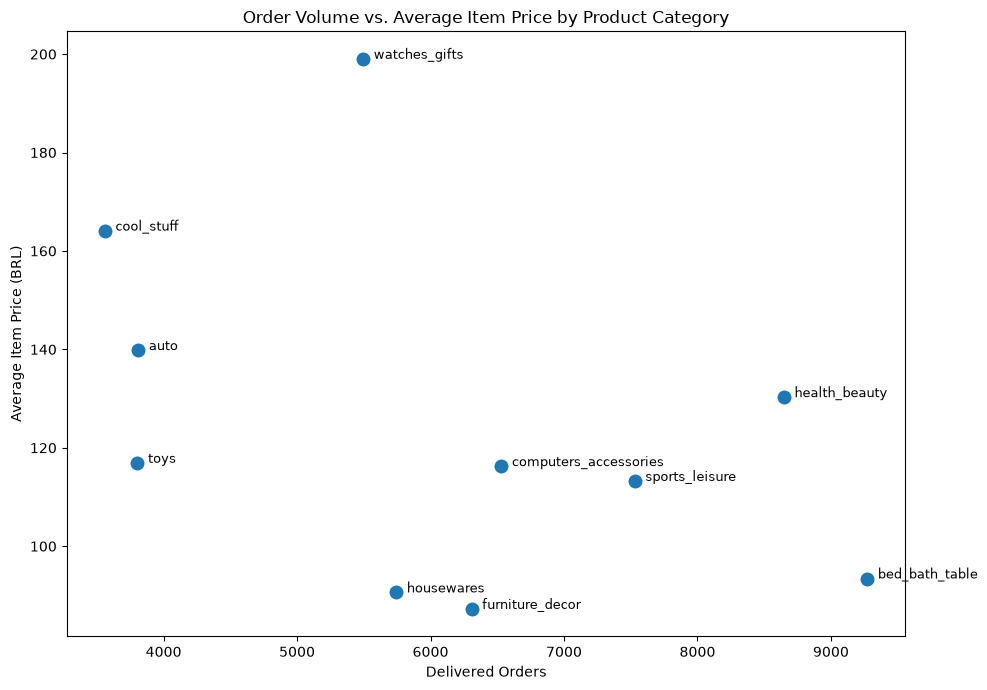

In [36]:
top10_driver = category_summary_detail.head(10)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=top10_driver,
    x="Orders",
    y="Avg_Item_Price",
    s=120
)

for _, row in top10_driver.iterrows():
    plt.text(
        row["Orders"] + 80,
        row["Avg_Item_Price"],
        row["category_english"],
        fontsize=9
    )

plt.title("Order Volume vs. Average Item Price by Product Category")
plt.xlabel("Delivered Orders")
plt.ylabel("Average Item Price (BRL)")

plt.tight_layout()
plt.show()

### Product Category Driver Comparison

The relationship between order volume and average item price highlights different category-level GMV strategies.

- `bed_bath_table` and `health_beauty` are strongly volume-driven, with some of the highest delivered order counts.
- `watches_gifts` is more price-driven, with a substantially higher average item price despite lower order volume.
- `cool_stuff` and `auto` also show relatively high average item prices but lower order volumes.
- `furniture_decor` and `housewares` rely more on transaction volume and purchase quantity than on high item prices.

These differences suggest that high GMV can result from different combinations of sales volume and product value across categories.

In [37]:
delivery_base = delivered_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "flag_delivered_before_carrier",
        "flag_delivered_missing_date"
    ]
].copy()

delivery_base = delivery_base[
    delivery_base["order_delivered_customer_date"].notna()
].copy()

delivery_base["delivery_days"] = (
    delivery_base["order_delivered_customer_date"]
    - delivery_base["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_base["delivery_delay_days"] = (
    delivery_base["order_delivered_customer_date"]
    - delivery_base["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery_base["is_late"] = (
    delivery_base["delivery_delay_days"] > 0
)

delivery_base[
    [
        "delivery_days",
        "delivery_delay_days",
        "is_late"
    ]
].describe()

,delivery_days,delivery_delay_days
count,96470.000000,96470.000000
mean,12.558217,-11.178126
std,9.546156,10.184354
min,0.533414,-146.016123
25%,6.766204,-16.244065
50%,10.217477,-11.948102
75%,15.720182,-6.389815
max,209.628611,188.975081


In [38]:
print(
    "Late delivery rate:",
    f"{delivery_base['is_late'].mean() * 100:.2f}%"
)

print(
    "Median delivery days:",
    f"{delivery_base['delivery_days'].median():.2f}"
)

print(
    "Average delivery days:",
    f"{delivery_base['delivery_days'].mean():.2f}"
)

Late delivery rate: 8.11%
Median delivery days: 10.22
Average delivery days: 12.56


### Delivery Performance Overview

Among delivered orders with recorded delivery dates:

- The median delivery time is 10.22 days.
- The average delivery time is 12.56 days.
- 8.11% of delivered orders arrived after the estimated delivery date.
- On average, orders were delivered approximately 11 days earlier than the estimated delivery date.

The average delivery time is higher than the median, indicating a right-skewed distribution with a relatively small number of long-delivery orders.

In [39]:
print("Delivery time percentiles:")
print(
    delivery_base["delivery_days"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
)

print("\nOrders taking more than 30 days:",
      (delivery_base["delivery_days"] > 30).sum())

print("Orders taking more than 60 days:",
      (delivery_base["delivery_days"] > 60).sum())

print("Orders taking more than 90 days:",
      (delivery_base["delivery_days"] > 90).sum())

Delivery time percentiles:
0.50    10.217477
0.75    15.720182
0.90    23.096377
0.95    29.274046
0.99    46.050262
Name: delivery_days, dtype: float64

Orders taking more than 30 days: 4550
Orders taking more than 60 days: 306
Orders taking more than 90 days: 77


In [40]:
delivery_analysis = delivery_base[
    ~delivery_base["flag_delivered_before_carrier"]
].copy()

print("Orders retained for delivery analysis:", len(delivery_analysis))
print(
    "Excluded timestamp-anomaly orders:",
    len(delivery_base) - len(delivery_analysis)
)

Orders retained for delivery analysis: 96447
Excluded timestamp-anomaly orders: 23


### Delivery Time Distribution

Delivery times show a right-skewed distribution:

- 50% of delivered orders arrived within 10.22 days.
- 90% arrived within 23.10 days.
- 95% arrived within 29.27 days.
- 99% arrived within 46.05 days.
- Approximately 4.72% of orders took more than 30 days to arrive, while deliveries exceeding 60 or 90 days were rare.

Long delivery times were retained because unusually slow delivery may represent genuine customer experience issues rather than data errors.

For delivery-related analysis, 23 orders with inconsistent timestamp sequences were excluded, leaving 96,447 valid delivered orders.

In [41]:
review_order = (
    reviews
    .groupby("order_id")
    .agg(
        avg_review_score=("review_score", "mean"),
        review_count=("review_id", "count")
    )
    .reset_index()
)

print("Orders with review records:", review_order["order_id"].nunique())
review_order.head()

Orders with review records: 98673


,order_id,avg_review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,4.0,1
2,000229ec398224ef6ca0657da4fc703e,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1


In [43]:
delivery_review = (
    delivery_analysis
    .merge(
        review_order,
        on="order_id",
        how="inner"
    )
)

print("Orders in delivery-review analysis:", len(delivery_review))
delivery_review["delivery_status"] = np.where(
    delivery_review["is_late"],
    "Late",
    "On-time"
)

delivery_review_summary = (
    delivery_review
    .groupby("delivery_status")
    .agg(
        Orders=("order_id", "nunique"),
        Avg_Review_Score=("avg_review_score", "mean"),
        Median_Review_Score=("avg_review_score", "median"),
        Avg_Delivery_Days=("delivery_days", "mean")
    )
    .reset_index()
)

delivery_review_summary

Orders in delivery-review analysis: 95801


,delivery_status,Orders,Avg_Review_Score,Median_Review_Score,Avg_Delivery_Days
0,Late,7661,2.566506,2.0,31.378793
1,On-time,88140,4.294686,5.0,10.878785


### Late Delivery and Customer Satisfaction

Late delivery is strongly associated with lower customer review scores.

- Late orders have an average review score of 2.57, compared with 4.29 for on-time orders.
- The median review score is 2 for late deliveries and 5 for on-time deliveries.
- Late orders take an average of 31.38 days to arrive, compared with 10.88 days for on-time orders.

These results suggest that delivery performance is closely related to customer satisfaction.

However, this is an observational relationship and should not be interpreted as proof that late delivery directly causes lower review scores.

In [44]:
delivery_review["low_rating"] = (
    delivery_review["avg_review_score"] <= 2
)

low_rating_summary = (
    delivery_review
    .groupby("delivery_status")
    .agg(
        Orders=("order_id", "nunique"),
        Low_Rating_Rate=("low_rating", "mean")
    )
    .reset_index()
)

low_rating_summary["Low_Rating_Rate"] *= 100

low_rating_summary

,delivery_status,Orders,Low_Rating_Rate
0,Late,7661,53.987730
1,On-time,88140,9.177445


### Low-Rating Risk by Delivery Status

Late delivery is associated with a substantially higher rate of low customer ratings.

- 53.99% of late orders received an average review score of 2 or below.
- Only 9.18% of on-time orders received similarly low ratings.
- The low-rating rate for late orders is approximately 5.88× that of on-time orders.

This reinforces the strong relationship between delivery performance and customer satisfaction, although the analysis remains observational and does not establish causality.

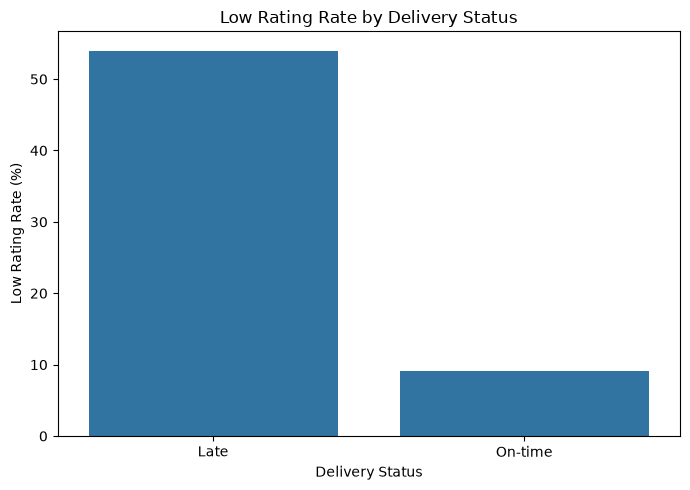

In [45]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=low_rating_summary,
    x="delivery_status",
    y="Low_Rating_Rate"
)

plt.title("Low Rating Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Low Rating Rate (%)")

plt.tight_layout()
plt.show()

In [47]:
def delay_bucket(days):
    if days <= 0:
        return "On-time / Early"
    elif days <= 3:
        return "1–3 days late"
    elif days <= 7:
        return "4–7 days late"
    elif days <= 14:
        return "8–14 days late"
    else:
        return "15+ days late"

delivery_review["delay_bucket"] = (
    delivery_review["delivery_delay_days"]
    .apply(delay_bucket)
)
delay_severity_summary = (
    delivery_review
    .groupby("delay_bucket")
    .agg(
        Orders=("order_id", "nunique"),
        Avg_Review_Score=("avg_review_score", "mean"),
        Low_Rating_Rate=("low_rating", "mean")
    )
    .reset_index()
)

delay_order = [
    "On-time / Early",
    "1–3 days late",
    "4–7 days late",
    "8–14 days late",
    "15+ days late"
]

delay_severity_summary["delay_bucket"] = pd.Categorical(
    delay_severity_summary["delay_bucket"],
    categories=delay_order,
    ordered=True
)

delay_severity_summary["Low_Rating_Rate"] *= 100

delay_severity_summary = (
    delay_severity_summary
    .sort_values("delay_bucket")
    .reset_index(drop=True)
)

delay_severity_summary

,delay_bucket,Orders,Avg_Review_Score,Low_Rating_Rate
0,On-time / Early,88140,4.294686,9.177445
1,1–3 days late,2636,3.766882,19.081942
2,4–7 days late,1773,2.317259,61.252115
3,8–14 days late,1748,1.745423,78.032037
4,15+ days late,1504,1.710771,78.656915


### Review Score by Delivery Delay Severity

Customer satisfaction deteriorates substantially as delivery delays become more severe.

- On-time or early deliveries have an average review score of 4.29 and a low-rating rate of 9.18%.
- Orders delivered 1–3 days late show a moderate decline in satisfaction, with an average score of 3.77.
- Once delays reach 4–7 days, the low-rating rate rises sharply to 61.25%.
- Delays of 8 days or more are associated with average review scores below 2 and low-rating rates of approximately 78%.

The relationship is strongly monotonic: longer delivery delays are associated with progressively worse customer reviews.

This analysis is observational and does not establish causality.

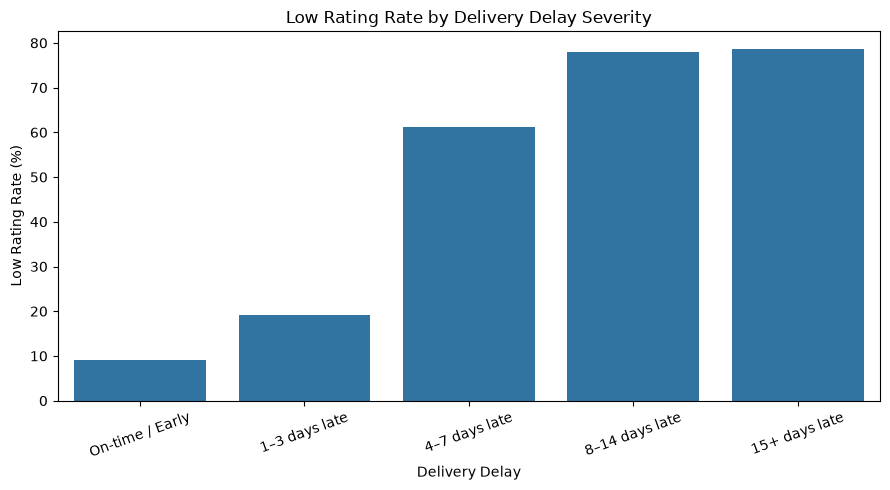

In [48]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=delay_severity_summary,
    x="delay_bucket",
    y="Low_Rating_Rate"
)

plt.title("Low Rating Rate by Delivery Delay Severity")
plt.xlabel("Delivery Delay")
plt.ylabel("Low Rating Rate (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

A particularly notable inflection occurs once delivery delays exceed 3 days: the low-rating rate increases from 19.08% for 1–3 day delays to 61.25% for 4–7 day delays.

In [49]:
payment_summary = (
    payments
    .groupby("payment_type")
    .agg(
        Payment_Records=("order_id", "count"),
        Orders=("order_id", "nunique"),
        Payment_Value=("payment_value", "sum")
    )
    .reset_index()
)

payment_summary["Payment_Value_Share_pct"] = (
    payment_summary["Payment_Value"]
    / payment_summary["Payment_Value"].sum()
    * 100
)

payment_summary = (
    payment_summary
    .sort_values("Payment_Value", ascending=False)
    .reset_index(drop=True)
)

payment_summary

,payment_type,Payment_Records,Orders,Payment_Value,Payment_Value_Share_pct
0,credit_card,76795,76505,12542084.19,78.344584
1,boleto,19784,19784,2869361.27,17.923569
2,voucher,5775,3866,379436.87,2.370166
3,debit_card,1529,1528,217989.79,1.361681
4,not_defined,3,3,0.00,0.000000


In [50]:
delivered_payments = payments[
    payments["order_id"].isin(delivered_orders["order_id"])
].copy()

delivered_payment_summary = (
    delivered_payments
    .groupby("payment_type")
    .agg(
        Payment_Records=("order_id", "count"),
        Orders=("order_id", "nunique"),
        Payment_Value=("payment_value", "sum")
    )
    .reset_index()
)

delivered_payment_summary["Payment_Value_Share_pct"] = (
    delivered_payment_summary["Payment_Value"]
    / delivered_payment_summary["Payment_Value"].sum()
    * 100
)

delivered_payment_summary = (
    delivered_payment_summary
    .sort_values("Payment_Value", ascending=False)
    .reset_index(drop=True)
)

delivered_payment_summary

,payment_type,Payment_Records,Orders,Payment_Value,Payment_Value_Share_pct
0,credit_card,74586,74304,12101094.88,78.464094
1,boleto,19191,19191,2769932.58,17.960379
2,voucher,5493,3679,343013.19,2.224114
3,debit_card,1486,1485,208421.12,1.351413


### Payment Method Distribution

Credit cards are the dominant payment method among delivered orders, accounting for 78.46% of total customer payment value.

- Credit card: 78.46%
- Boleto: 17.96%
- Voucher: 2.22%
- Debit card: 1.35%

The payment mix is therefore highly concentrated in credit cards, making installment behavior an important component of customer payment analysis.

In [51]:
credit_card_payments = delivered_payments[
    (delivered_payments["payment_type"] == "credit_card")
    & (delivered_payments["payment_installments_clean"].notna())
].copy()

installment_summary = (
    credit_card_payments
    .groupby("payment_installments_clean")
    .agg(
        Payment_Records=("order_id", "count"),
        Orders=("order_id", "nunique"),
        Payment_Value=("payment_value", "sum"),
        Avg_Payment_Value=("payment_value", "mean")
    )
    .reset_index()
)

installment_summary["Order_Share_pct"] = (
    installment_summary["Orders"]
    / installment_summary["Orders"].sum()
    * 100
)

installment_summary = installment_summary.sort_values(
    "payment_installments_clean"
).reset_index(drop=True)

installment_summary

,payment_installments_clean,Payment_Records,Orders,Payment_Value,Avg_Payment_Value,Order_Share_pct
0,1.0,24759,24711,2366960.73,95.600013,33.192295
1,2.0,12075,12052,1528581.69,126.590616,16.188481
2,3.0,10164,10147,1443288.05,142.000005,13.629648
3,4.0,6891,6882,1127647.37,163.640599,9.244036
4,5.0,5095,5090,928837.73,182.303774,6.836987
5,6.0,3804,3800,793288.80,208.540694,5.104234
6,7.0,1563,1560,290643.18,185.952131,2.095422
7,8.0,4136,4122,1266801.58,306.286649,5.536750
8,9.0,618,618,122346.20,197.971197,0.830110
9,10.0,5150,5137,2114267.90,410.537456,6.900118


In [52]:
def installment_bucket(x):
    if x == 1:
        return "1 installment"
    elif x <= 3:
        return "2–3 installments"
    elif x <= 6:
        return "4–6 installments"
    elif x <= 9:
        return "7–9 installments"
    else:
        return "10+ installments"


credit_card_payments["installment_bucket"] = (
    credit_card_payments["payment_installments_clean"]
    .apply(installment_bucket)
)

installment_bucket_summary = (
    credit_card_payments
    .groupby("installment_bucket")
    .agg(
        Orders=("order_id", "nunique"),
        Payment_Value=("payment_value", "sum"),
        Avg_Payment_Value=("payment_value", "mean")
    )
    .reset_index()
)

bucket_order = [
    "1 installment",
    "2–3 installments",
    "4–6 installments",
    "7–9 installments",
    "10+ installments"
]

installment_bucket_summary["installment_bucket"] = pd.Categorical(
    installment_bucket_summary["installment_bucket"],
    categories=bucket_order,
    ordered=True
)

installment_bucket_summary["Order_Share_pct"] = (
    installment_bucket_summary["Orders"]
    / installment_bucket_summary["Orders"].sum()
    * 100
)

installment_bucket_summary = (
    installment_bucket_summary
    .sort_values("installment_bucket")
    .reset_index(drop=True)
)

installment_bucket_summary

,installment_bucket,Orders,Payment_Value,Avg_Payment_Value,Order_Share_pct
0,1 installment,24711,2366960.73,95.600013,33.203891
1,2–3 installments,22189,2971869.74,133.633245,29.815108
2,4–6 installments,15757,2849773.90,180.479664,21.172503
3,7–9 installments,6299,1679790.96,265.915935,8.463895
4,10+ installments,5466,2232510.92,407.466859,7.344602


### Credit Card Installment Behavior

Credit card payments are concentrated in relatively short installment plans.

- 33.20% of credit card orders use a single installment.
- 29.82% use 2–3 installments.
- Together, 1–3 installment plans account for approximately 63% of credit card orders.
- Longer installment plans are less common but are associated with substantially higher average payment values.
- Average payment value rises from 95.60 BRL for single-installment payments to 407.47 BRL for payments with 10 or more installments.

This suggests that customers tend to use longer installment plans for higher-value purchases.

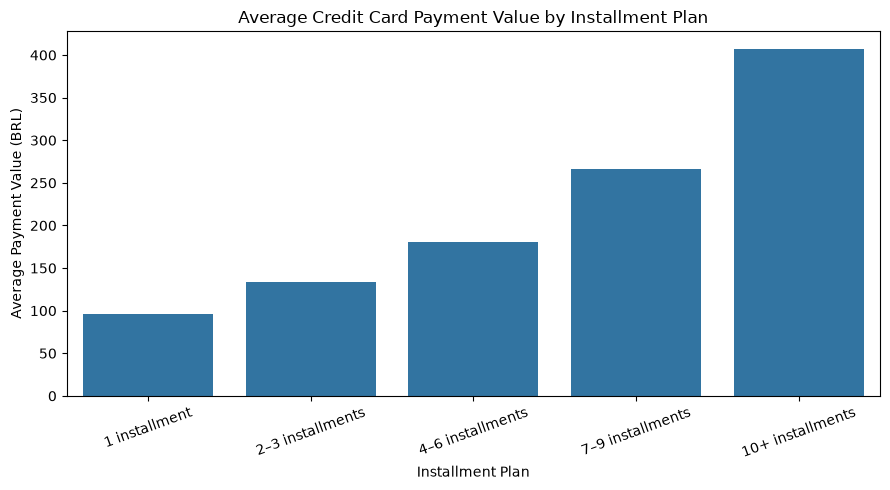

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=installment_bucket_summary,
    x="installment_bucket",
    y="Avg_Payment_Value"
)

plt.title("Average Credit Card Payment Value by Installment Plan")
plt.xlabel("Installment Plan")
plt.ylabel("Average Payment Value (BRL)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Longer installment plans are associated with progressively higher average payment values, suggesting that customers tend to use extended credit terms for higher-value purchases.

In [54]:
seller_summary = (
    product_sales_base
    .groupby("seller_id")
    .agg(
        GMV=("price", "sum"),
        Orders=("order_id", "nunique"),
        Items=("product_id", "count")
    )
    .reset_index()
)

seller_summary["GMV_per_Order"] = (
    seller_summary["GMV"]
    / seller_summary["Orders"]
)

seller_summary["GMV_share_pct"] = (
    seller_summary["GMV"]
    / seller_summary["GMV"].sum()
    * 100
)

seller_summary = (
    seller_summary
    .sort_values("GMV", ascending=False)
    .reset_index(drop=True)
)

print("Number of active sellers:", seller_summary["seller_id"].nunique())

seller_summary.head(10)

Number of active sellers: 2970


,seller_id,GMV,Orders,Items,GMV_per_Order,GMV_share_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1124,1148,201.946557,1.716809
1,53243585a1d6dc2643021fd1853d8905,217940.44,348,400,626.265632,1.648379
2,4a3ca9315b744ce9f8e9374361493884,196882.12,1772,1949,111.107291,1.489106
3,fa1c13f2614d7b5c4749cbc52fecda94,190917.14,578,579,330.306471,1.443990
4,7c67e1448b00f6e969d365cea6b010ab,186570.05,973,1355,191.747225,1.411111
5,7e93a43ef30c4f03f38b393420bc753a,165981.49,319,322,520.318150,1.255391
6,da8622b14eb17ae2831f4ac5b9dab84a,159816.87,1311,1548,121.904554,1.208765
7,7a67c85e85bb2ce8582c35f2203ad736,139658.69,1145,1155,121.972655,1.056300
8,1025f0e2d44d7041d6cf58b6550e0bfa,138208.56,910,1420,151.877538,1.045332
9,955fee9216a65b617aa5c0531780ce60,131836.71,1261,1472,104.549334,0.997139


In [55]:
top10_seller_share = (
    seller_summary.head(10)["GMV"].sum()
    / seller_summary["GMV"].sum()
    * 100
)

top50_seller_share = (
    seller_summary.head(50)["GMV"].sum()
    / seller_summary["GMV"].sum()
    * 100
)

top100_seller_share = (
    seller_summary.head(100)["GMV"].sum()
    / seller_summary["GMV"].sum()
    * 100
)

print(f"Top 10 seller GMV share: {top10_seller_share:.2f}%")
print(f"Top 50 seller GMV share: {top50_seller_share:.2f}%")
print(f"Top 100 seller GMV share: {top100_seller_share:.2f}%")

Top 10 seller GMV share: 13.27%
Top 50 seller GMV share: 33.20%
Top 100 seller GMV share: 45.52%


### Seller GMV Concentration

GMV is relatively distributed across sellers rather than being dominated by a small number of top merchants.

- The top 10 sellers contribute 13.27% of delivered-order GMV.
- The top 50 sellers contribute 33.20%.
- The top 100 sellers contribute 45.52%.

This indicates that marketplace GMV is supported by a relatively broad seller base, with no small group of sellers accounting for the majority of transaction value.

In [58]:
seller_summary["cumulative_GMV_share_pct"] = (
    seller_summary["GMV"].cumsum()
    / seller_summary["GMV"].sum()
    * 100
)

sellers_for_50pct = (
    seller_summary["cumulative_GMV_share_pct"]
    .ge(50)
    .idxmax()
    + 1
)

sellers_for_80pct = (
    seller_summary["cumulative_GMV_share_pct"]
    .ge(80)
    .idxmax()
    + 1
)

print("Sellers needed for 50% of GMV:", sellers_for_50pct)
print("Sellers needed for 80% of GMV:", sellers_for_80pct)

Sellers needed for 50% of GMV: 127
Sellers needed for 80% of GMV: 533


### Seller Concentration

The marketplace contains 2,970 active sellers.

- The top 127 sellers generate 50% of delivered-order GMV.
- The top 533 sellers generate 80% of delivered-order GMV.
- This means that approximately 4.3% of active sellers account for half of GMV, while about 17.9% account for 80%.

The seller base therefore shows meaningful concentration, but GMV is not dominated by only a handful of merchants.

## Key Insights Summary

The exploratory analysis highlights several important patterns in marketplace performance, customer behavior, product mix, delivery experience, payments, and seller concentration.

### 1. Marketplace Growth
Monthly GMV increased substantially from early 2017 through mid-2018. Delivered order volume followed a very similar pattern, while AOV remained relatively stable.

This suggests that GMV growth was driven primarily by increasing transaction volume rather than a sustained increase in customer spending per order.

### 2. Customer Purchase Behavior
The customer base is dominated by one-time purchasers:

- 97.0% of customers placed only one delivered order.
- Only 3.0% of customers were repeat customers.
- Repeat customers generated 5.51% of total GMV.
- Repeat customers generated approximately 260.05 BRL in GMV per customer, compared with 137.96 BRL for one-time customers.

Although repeat customers have a lower AOV, they generate more GMV per customer because they place more orders on average.

### 3. Geographic Concentration
GMV is geographically concentrated:

- São Paulo (SP) contributes 38.33% of total delivered-order GMV.
- Rio de Janeiro (RJ) contributes 13.31%.
- Minas Gerais (MG) contributes 11.74%.

The top three states together account for approximately 63.38% of GMV.

Differences in state-level GMV are driven mainly by order volume rather than AOV. Among the top 10 states, the order-volume max/min ratio is 20.7×, while the AOV ratio is only 1.21×.

### 4. Product Category Drivers
The highest-GMV categories include:

- `health_beauty`
- `watches_gifts`
- `bed_bath_table`
- `sports_leisure`
- `computers_accessories`

Different categories generate GMV through different combinations of order volume, item price, and purchase quantity.

For example:

- `health_beauty` combines high order volume with relatively strong item prices.
- `watches_gifts` is more price-driven, with an average item price of approximately 199 BRL.
- `bed_bath_table` is more volume-driven, with the highest delivered-order count among the top categories.
- `furniture_decor` has a relatively high number of items per category-level order.

### 5. Delivery Performance and Customer Satisfaction
Delivery performance is strongly associated with customer review outcomes.

- Median delivery time is 10.22 days.
- Average delivery time is 12.56 days.
- 8.11% of delivered orders arrive after the estimated delivery date.

Late deliveries receive substantially worse customer feedback:

- Average review score for on-time orders: 4.29
- Average review score for late orders: 2.57
- Low-rating rate for on-time orders: 9.18%
- Low-rating rate for late orders: 53.99%

The effect becomes especially pronounced once delays exceed three days:

- 1–3 days late: 19.08% low-rating rate
- 4–7 days late: 61.25%
- 8–14 days late: 78.03%
- 15+ days late: 78.66%

This indicates a strong association between delivery delay severity and customer dissatisfaction, although the observational analysis does not establish causality.

### 6. Payment Behavior
Credit cards dominate customer payments for delivered orders:

- Credit card: 78.46%
- Boleto: 17.96%
- Voucher: 2.22%
- Debit card: 1.35%

Credit card installment behavior also varies strongly with purchase value.

Approximately 63% of credit-card orders use 1–3 installments, while longer installment plans are less common.

Average payment value increases substantially across installment groups:

- 1 installment: 95.60 BRL
- 2–3 installments: 133.63 BRL
- 4–6 installments: 180.48 BRL
- 7–9 installments: 265.92 BRL
- 10+ installments: 407.47 BRL

This suggests that longer installment plans are generally associated with higher-value purchases.

### 7. Seller Concentration
There are 2,970 active sellers in delivered-order transactions.

Seller GMV shows meaningful but not extreme concentration:

- Top 10 sellers generate 13.27% of GMV.
- Top 50 sellers generate 33.20%.
- Top 100 sellers generate 45.52%.
- 127 sellers are required to generate 50% of GMV.
- 533 sellers are required to generate 80% of GMV.

Overall, the marketplace relies on a broad seller base rather than a very small number of dominant merchants.

## Overall Business Takeaway

Marketplace growth appears to be driven primarily by increasing transaction volume. At the same time, customer repeat purchasing remains limited, suggesting that customer retention and repeat purchase behavior may represent an important opportunity for further analysis.

Delivery performance also emerges as a major customer-experience signal: longer delivery delays are strongly associated with lower review scores and substantially higher low-rating rates.

Product, geographic, payment, and seller analyses further show that GMV is shaped by multiple distinct drivers, including order volume, product value, payment behavior, and market concentration.

In [59]:
import sqlite3

db_path = "../data/processed/olist_analytics.db"

conn = sqlite3.connect(db_path)

# Reload processed CSVs so the SQL database contains
# cleaned data rather than temporary EDA-only columns.

sql_orders = pd.read_csv("../data/processed/orders_clean.csv")
sql_customers = pd.read_csv("../data/processed/customers_clean.csv")
sql_order_items = pd.read_csv("../data/processed/order_items_clean.csv")
sql_payments = pd.read_csv("../data/processed/payments_clean.csv")
sql_reviews = pd.read_csv("../data/processed/reviews_clean.csv")
sql_products = pd.read_csv("../data/processed/products_clean.csv")
sql_sellers = pd.read_csv("../data/processed/sellers_clean.csv")
sql_category_translation = pd.read_csv(
    "../data/processed/category_translation_clean.csv"
)

sql_orders.to_sql("orders", conn, if_exists="replace", index=False)
sql_customers.to_sql("customers", conn, if_exists="replace", index=False)
sql_order_items.to_sql("order_items", conn, if_exists="replace", index=False)
sql_payments.to_sql("payments", conn, if_exists="replace", index=False)
sql_reviews.to_sql("reviews", conn, if_exists="replace", index=False)
sql_products.to_sql("products", conn, if_exists="replace", index=False)
sql_sellers.to_sql("sellers", conn, if_exists="replace", index=False)
sql_category_translation.to_sql(
    "category_translation",
    conn,
    if_exists="replace",
    index=False
)

conn.close()

print("SQLite database created successfully!")

SQLite database created successfully!
